In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [44]:
df = pd.read_csv("uber.csv")

# Remove unnecessary columns
df.drop(columns=['Unnamed: 0', 'key'], inplace=True, errors='ignore')

# Remove missing values
df.dropna(inplace=True)

# Convert pickup datetime
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

# Extract useful date features
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month

df.drop(columns=['pickup_datetime'], inplace=True)

# Remove invalid values
df = df[(df['fare_amount'] > 0) & 
        (df['passenger_count'] > 0)]

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8


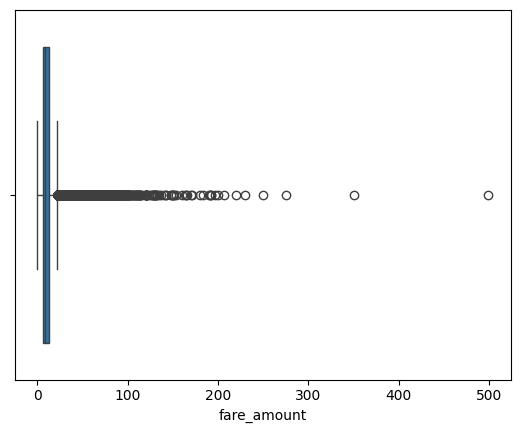

Dataset shape after removing outliers: (182148, 9)


In [45]:
# Boxplot to identify outliers
sns.boxplot(x=df['fare_amount'])
plt.show()

# Remove outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

df = df[
    (df['fare_amount'] >= Q1 - 1.5 * IQR) &
    (df['fare_amount'] <= Q3 + 1.5 * IQR)
]

print("Dataset shape after removing outliers:", df.shape)

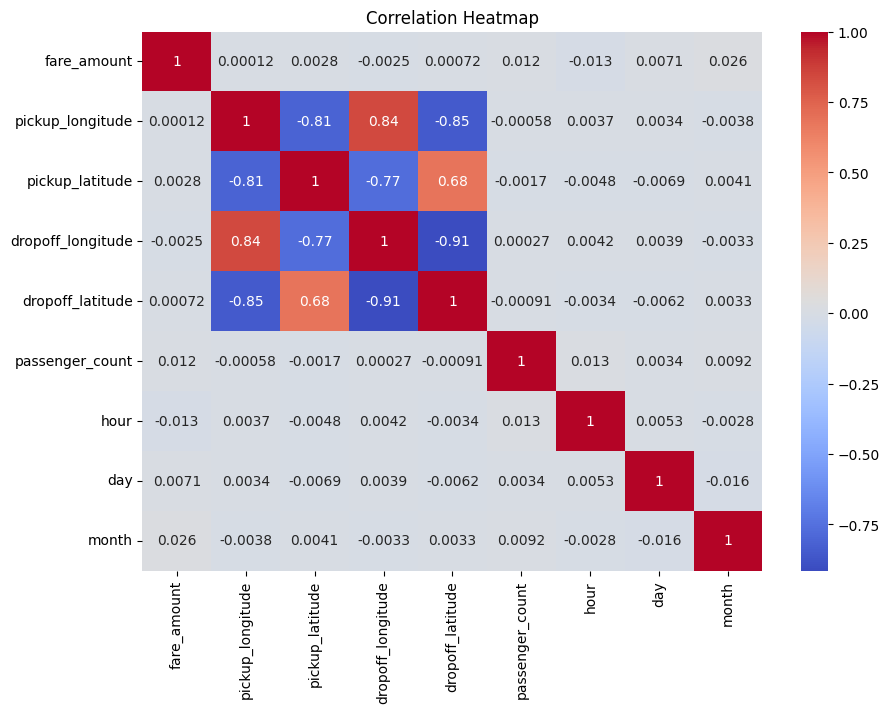

In [46]:
plt.figure(figsize=(10, 7))

sns.heatmap(df.corr(numeric_only=True),
            annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [47]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [48]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [49]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [53]:
def evaluate_model(y_test, y_pred):
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    return r2, rmse, mae

lr_scores = evaluate_model(y_test, y_pred_lr)
rf_scores = evaluate_model(y_test, y_pred_rf)

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [lr_scores[0], rf_scores[0]],
    'RMSE': [lr_scores[1], rf_scores[1]],
    'MAE': [lr_scores[2], rf_scores[2]]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.001313  4.126793  3.281215
1      Random Forest  0.718603  2.190572  1.528581


In [51]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_rf)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf)
    ]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.001313  4.126793  3.281215
1      Random Forest  0.718603  2.190572  1.528581


In [52]:
# Example pickup and drop-off coordinates
sample = pd.DataFrame([{
    'pickup_longitude': -73.985,
    'pickup_latitude': 40.748,
    'dropoff_longitude': -73.985,
    'dropoff_latitude': 40.758,
    'passenger_count': 1,
    'hour': 14,
    'day': 15,
    'month': 6
}])

predicted_fare = rf.predict(sample)

print("Predicted Uber Fare: $", round(predicted_fare[0], 2))

Predicted Uber Fare: $ 6.81
